# The sunspot cycle: how far ahead is a forecast worth making?

**Scored over the eleven years ahead, our regression tied with "the same as eleven years ago". For next year alone it was almost twice as good. From the third year on it added nothing.**

Sunspots come and go in a cycle of about eleven years, never exactly eleven and never the same height twice. That makes them a fair stand-in for anything regular enough to forecast and irregular enough to get wrong, from flu seasons to business cycles. We forecast the yearly sunspot number eleven years ahead from 179 different start years. The question is not which forecaster wins, but how many years ahead each one is worth listening to, and whether a cleverer model could do better.

*Data: yearly sunspot numbers, 1700 to 1988, from R's datasets package ([source and license](data/README.md#sunspots)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

from timegym import LastValueForecaster, MeanForecaster, Pipeline, SeasonalLastValueForecaster, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The cycle

One number per year: an index of how many spots, and groups of spots, were seen on the sun. The first forecasts start in 1800, so every forecaster has at least a century of history to learn from.

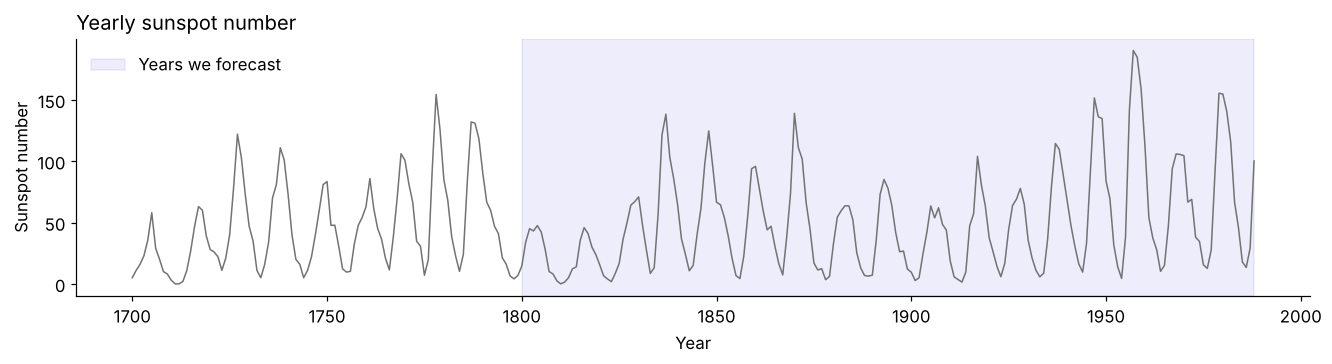

289 years, 1700 to 1988.


In [2]:
sunspots = load("sunspots")
horizon = 11
first = 100   # the first forecast is made with 100 years of history

fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
years = sunspots.index.year
ax.plot(years, sunspots["sunspots"], color="0.45", linewidth=1)
ax.axvspan(years[first], years[-1], color="#0000CC", alpha=0.07, label="Years we forecast")
ax.set(title="Yearly sunspot number", xlabel="Year", ylabel="Sunspot number")
ax.legend(loc="upper left")
plt.show()
print(f"{len(sunspots)} years, {years[0]} to {years[-1]}.")

## Four forecasters, 179 start years

- **Long-run average** forecasts the average of all the history, every year ahead.
- **Last year** repeats the latest value.
- **Same year one cycle ago** repeats the value from eleven years before the year being forecast. It fits nothing.
- **Regression on 9 years** is a linear regression that predicts each year from the nine before it. To go further ahead it feeds its own forecasts back in.

`cases_from_series` makes one case for each start year from 1800 to 1978: the history up to that year, and the eleven years to forecast. Every forecaster runs on the same 179 cases, and is fitted again for each one on the history it is given.

In [3]:
cases = cases_from_series(sunspots, origins=range(first, len(sunspots) - horizon + 1), horizon=horizon, name="sunspots")

forecasters = {"Long-run average": Pipeline(MeanForecaster()),
               "Last year": Pipeline(LastValueForecaster()),
               "Same year one cycle ago": Pipeline(SeasonalLastValueForecaster(period=11)),
               "Regression on 9 years": Pipeline(LinearRegression(), window_length=9)}
runs = {name: pipeline.run(cases=cases, keep_data=True) for name, pipeline in forecasters.items()}

actual = np.array([case.observed["sunspots"].to_numpy() for case in cases])


def misses(run):
    "How far off each forecast was: one row per start year, one column per year ahead."
    return np.abs(np.array([entry.forecast.point[:, 0] for entry in run.cases]) - actual)


miss = {name: misses(run) for name, run in runs.items()}
overall = pd.Series({name: values.mean() for name, values in miss.items()}, name="Average miss over the 11 years")
display(overall.round(1).to_frame())
print(f"{len(cases)} start years, {horizon} years ahead each.")
assert abs(overall["Regression on 9 years"] - overall["Same year one cycle ago"]) < 0.5
assert overall["Long-run average"] > 1.5 * overall["Regression on 9 years"]

,Average miss over the 11 years
Long-run average,32.3
Last year,40.0
Same year one cycle ago,20.5
Regression on 9 years,20.4


179 start years, 11 years ahead each.


A tie. The regression, the only one of the four with anything to fit, misses by 20.4 on average, and the rule that copies the value from eleven years back misses by 20.5. Both are far ahead of the long-run average, and "last year" is worst of all.

If we stopped here we would conclude that the regression is not worth having. That would be wrong, and the run already holds the evidence.

## The same forecasts, by years ahead

Each forecast covers eleven years, and the run kept all of them. Averaging the miss separately for the first year ahead, the second, and so on gives a curve for each forecaster.

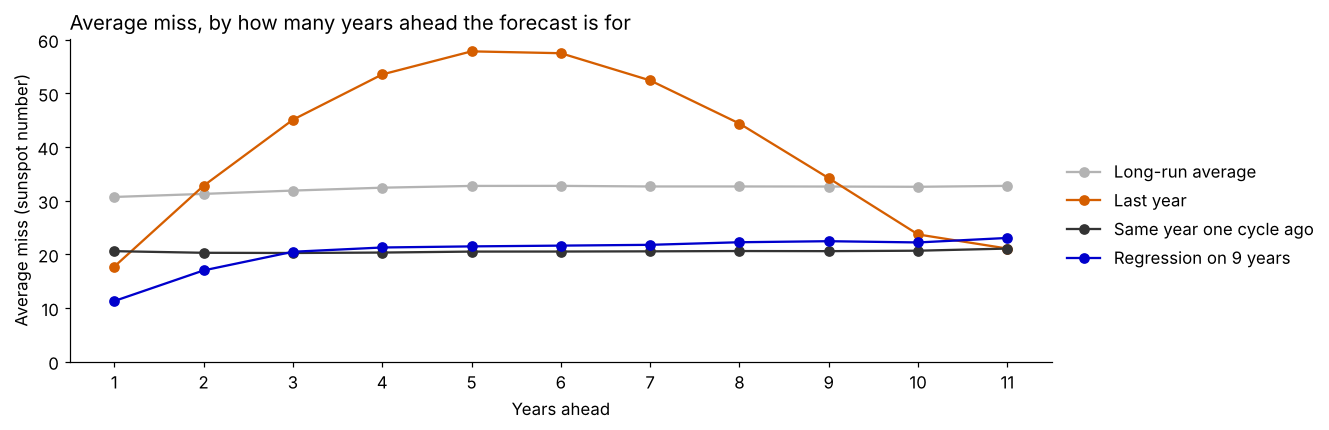

Years ahead,1,2,3,4,5,6,7,8,9,10,11
Long-run average,30.7,31.2,31.9,32.4,32.7,32.7,32.6,32.6,32.6,32.6,32.7
Last year,17.7,32.8,45.1,53.5,57.8,57.5,52.4,44.4,34.2,23.7,21.1
Same year one cycle ago,20.6,20.3,20.2,20.3,20.5,20.5,20.5,20.6,20.6,20.7,21.1
Regression on 9 years,11.3,17.0,20.5,21.3,21.5,21.6,21.8,22.2,22.4,22.2,23.0


In [4]:
by_step = pd.DataFrame({name: values.mean(axis=0) for name, values in miss.items()},
                       index=pd.RangeIndex(1, horizon + 1, name="Years ahead"))

colors = {"Long-run average": "0.7", "Last year": "#D55E00",
          "Same year one cycle ago": "0.2", "Regression on 9 years": "#0000CC"}
fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
for name, color in colors.items():
    ax.plot(by_step.index, by_step[name], color=color, marker="o", label=name)
ax.set(title="Average miss, by how many years ahead the forecast is for", xlabel="Years ahead",
       ylabel="Average miss (sunspot number)", xticks=by_step.index, ylim=(0, None))
fig.legend(loc="outside right center")
plt.show()
display(by_step.round(1).T)

regression, cycle_ago, last_year = (by_step[name] for name in ("Regression on 9 years", "Same year one cycle ago", "Last year"))
assert regression[1] < 0.6 * cycle_ago[1] and regression[2] < 0.9 * cycle_ago[2]
assert (regression.loc[3:] > cycle_ago.loc[3:] - 0.5).all()
assert last_year.idxmax() in (5, 6) and last_year[11] < 0.4 * last_year.max()

The tie was an average of two very different stretches.

- For **next year** the regression misses by 11 and the cycle rule by 21. For the year after it is still ahead, 17 against 20.
- From the **third year** on, the regression is no better than the cycle rule, and slightly worse at every step.
- The cycle rule is flat. It is as good, or as bad, eleven years ahead as one.
- **Last year** traces the cycle itself: fine one year ahead, worst of all at five or six years, when the sun is at the opposite point of its cycle, and good again at eleven, when the cycle has come round.

So the regression is worth having for two years. Past that, it has nothing to say that "one cycle ago" does not already say for free.

## Does that hold in both halves of the record?

A breakdown like this can be an accident of the years we happened to test. A cheap check is to cut the start years in two and see whether each half tells the same story.

In [5]:
start_year = np.array([case.observed.index[0].year for case in cases])
early = start_year < 1890
halves = {}
for label, chosen in ((f"Start years {start_year[early].min()} to {start_year[early].max()}", early),
                      (f"Start years {start_year[~early].min()} to {start_year[~early].max()}", ~early)):
    for name in ("Regression on 9 years", "Same year one cycle ago"):
        steps = miss[name][chosen].mean(axis=0)
        halves[(label, name)] = {"1 year ahead": steps[0], "2 years ahead": steps[1],
                                 "3 to 11 years ahead": steps[2:].mean()}
halves = pd.DataFrame(halves).T
display(halves.round(1))

for label in halves.index.get_level_values(0).unique():
    half = halves.loc[label]
    assert half.loc["Regression on 9 years", "1 year ahead"] < 0.65 * half.loc["Same year one cycle ago", "1 year ahead"]
    assert half.loc["Regression on 9 years", "2 years ahead"] < half.loc["Same year one cycle ago", "2 years ahead"]
    assert half.loc["Regression on 9 years", "3 to 11 years ahead"] > half.loc["Same year one cycle ago", "3 to 11 years ahead"] - 0.5

1 year ahead  2 years ahead  \
Start years 1800 to 1889 Regression on 9 years            10.3           17.2   
                         Same year one cycle ago          20.3           19.2   
Start years 1890 to 1978 Regression on 9 years            12.3           16.7   
                         Same year one cycle ago          20.8           21.4   

                                                  3 to 11 years ahead  
Start years 1800 to 1889 Regression on 9 years                   21.3  
                         Same year one cycle ago                 18.8  
Start years 1890 to 1978 Regression on 9 years                   22.3  
                         Same year one cycle ago                 22.4

Both halves agree on the part that matters. One and two years ahead, the regression leads in each. From three years on the regression has no lead: in the early half the cycle rule is clearly ahead, and in the late half the two are level.

## A longer look back made it worse

Nine years of look-back was a guess. It is natural to think that showing the regression more of the past can only help, so we try other lengths on the same cases. We also record the lowest value each version ever forecast, because a sunspot number cannot be negative.

In [6]:
rows = {}
for window in (3, 9, 22, 33, 44):
    run = Pipeline(LinearRegression(), window_length=window).run(cases=cases, keep_data=True)
    forecast = np.array([entry.forecast.point[:, 0] for entry in run.cases])
    rows[window] = {"Average miss over the 11 years": np.abs(forecast - actual).mean(),
                    "Lowest forecast": forecast.min(),
                    "Forecasts below zero (%)": 100 * (forecast < 0).mean(),
                    "Output checks failed": run.report.summary["status_counts"]["FAIL"]}
windows = pd.DataFrame(rows).T.rename_axis("Years of look-back")
display(windows.round({"Average miss over the 11 years": 1, "Lowest forecast": 0, "Forecasts below zero (%)": 1}))

assert windows["Average miss over the 11 years"].idxmin() == 9
assert windows.loc[44, "Average miss over the 11 years"] > 1.5 * windows.loc[9, "Average miss over the 11 years"]
assert windows.loc[44, "Lowest forecast"] < -100 and (windows["Output checks failed"] == 0).all()

,Average miss over the 11 years,Lowest forecast,Forecasts below zero (%),Output checks failed
Years of look-back,,,,
3,26.0,-25.0,1.1,0.0
9,20.4,-15.0,0.7,0.0
22,21.9,-55.0,2.4,0.0
33,24.6,-103.0,3.9,0.0
44,34.8,-643.0,8.1,0.0


Nine years is the best of these. With 44 years of look-back the regression is worse than the long-run average, and somewhere it forecast a sunspot number of minus 643. Fed its own forecasts eleven times over, a regression with that many weights can run away.

Two things to take from the table. The look-back is a setting to test, not to assume, and testing it took one loop over the same cases. And the output checks passed every time: they confirm that a forecast has the right dates and shape and contains real numbers, not that the numbers are possible for the thing being forecast. Even the 9-year version dips below zero now and then. TimeGym does not know what a sunspot is; a floor at zero is ours to add.

## Could a cleverer model do better?

The regression ties with a rule of thumb beyond two years. Either the regression is too simple, or the cycle is too irregular for anyone. Real data cannot tell these apart, because we never learn what the best possible forecast would have been.

The scorecard can, on generated series. We run it on two kinds of cycle: one that repeats exactly, and one whose rhythm wanders. With `attainable=True` it also scores, on each row, a forecaster built to match the way that row's series were generated, which marks what is attainable there.

In [7]:
card = forecasters["Regression on 9 years"].run(
    ["seasonal", "cycles"], history_length=first, horizon=horizon,
    attainable=True, instances=30, title="Regression on 9 years").scorecard
rows = card.table[["title", "noise", "score", "score_low", "score_high", "attainable"]].round(0)
rows = rows.set_axis(["Kind of series", "Noise", "Regression on 9 years", "Low end", "High end", "Attainable"], axis=1)
display(rows.set_index(["Kind of series", "Noise"]).astype(int))

room = (rows["Attainable"] - rows["Regression on 9 years"]).to_numpy()
assert (room[:2] > 15).all() and (room[2:] < 8).all()

Regression on 9 years  Low end  High end  \
Kind of series           Noise                                                  
Repeating seasonal cycle Low noise                      73       65        79   
                         High noise                     76       69        81   
Irregular cycles (AR(2)) Low noise                      84       67        92   
                         High noise                     88       81        92   

                                     Attainable  
Kind of series           Noise                   
Repeating seasonal cycle Low noise           97  
                         High noise          97  
Irregular cycles (AR(2)) Low noise           89  
                         High noise          91

On a cycle that repeats exactly, the regression scores 73 and 76 where 97 is attainable. There is a lot of room: a model that learned the exact length of the cycle would forecast it many years ahead.

On cycles whose rhythm wanders, it scores 84 and 88 where 89 and 91 are attainable. Almost no room. When the cycle is irregular, this simple regression is already close to the best that can be done, and what remains cannot be predicted by anyone. (The low and high ends show how much the regression's score would move with other generated series: the first irregular row is the least certain.)

The sun sits somewhere between the two. One sign of where: the cycle rule is sensitive to the length it assumes. With 10 or 12 years in place of 11 it misses by a fifth to a quarter more, as the next table shows, and the real cycle does not keep to any one length.

In [8]:
lengths = pd.Series({length: misses(Pipeline(SeasonalLastValueForecaster(period=length)).run(cases=cases, keep_data=True)).mean()
                     for length in (9, 10, 11, 12, 13)}, name="Average miss over the 11 years").rename_axis("Cycle length assumed (years)")
display(lengths.round(1).to_frame().T)
assert lengths.idxmin() == 11 and lengths[10] > 1.15 * lengths[11] and lengths[12] > 1.15 * lengths[11]

Cycle length assumed (years),9,10,11,12,13
Average miss over the 11 years,37.1,24.7,20.5,25.9,36.6


## What TimeGym added

- 179 start years in one line, each forecaster fitted again on the history before each one, and the simple rules to compare against run on exactly the same cases.
- Every forecast kept. The by-years-ahead curve, the two halves and the count of impossible values all came from the same four runs, with nothing fitted again.
- A scorecard that separates "the model is too simple" from "the thing is too irregular", by marking what is attainable on cycles of each kind.

What we would do with it: use the regression for the next two years, quote "the same as one cycle ago" beyond that, and say plainly that nothing here is worth much more than a rule of thumb past year two.

## Change one thing

- Give the regression a model for each year ahead in place of feeding its forecasts back in: `Pipeline(LinearRegression(), window_length=9, reduction="direct")`.
- Keep forecasts at or above zero by forecasting on another scale: `target_transform=BoxCoxTransform()` from `timegym.target` needs positive values, so add 1 to the series first.
- Forecast 22 years ahead with `horizon=22` and see whether "last year" comes round a second time.
- Swap `LinearRegression()` for any scikit-learn regressor and look at the first two years.

**What this doesn't show.** These are the yearly numbers as published up to 1988; the series has since been revised and extended by its keepers. Real sunspot forecasts use physics and measurements of the sun that are not in this series. Four simple forecasters are not a search for the best model. The generated cycles on the scorecard are not the sun: they show how much room a kind of series leaves, not what the sun allows.

**Related:** [Reductions](../tutorials/05_reductions.ipynb) explains the two ways a regression forecasts several steps ahead, [Capability sweeps](../tutorials/10_capability_sweeps.ipynb) varies a setting across generated series, and [How to read a score](../docs/concepts/scope.md#how-to-read-a-score) covers the scorecard's numbers. More examples are on the [examples page](../docs/examples.md).